<a href="https://colab.research.google.com/github/KaviduIsura/EuroSAT-Land-Use-Classification/blob/main/eurosat-cw1/notebooks/05_mlp_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🟡 Notebook 05 — Neural Model 1: PyTorch MLP
**NB6057CEM CW1 | T3b (part of 14 marks)**

Two-hidden-layer fully connected MLP in PyTorch. Trained with Adam, dropout regularisation, and early stopping.

**Architecture:** Flatten(12288) → Linear(512) → ReLU → Dropout → Linear(256) → ReLU → Dropout → Linear(10)

---

## Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import numpy as np
import matplotlib.pyplot as plt
import json, os, time, csv
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from google.colab import drive

drive.mount('/content/drive')

# Restore splits and preprocessing from Drive if not found locally
os.makedirs('splits', exist_ok=True)
os.makedirs('figures', exist_ok=True)
os.makedirs('metrics', exist_ok=True)
os.makedirs('checkpoints', exist_ok=True)

if not os.path.exists('splits/split_indices.npz'):
    print('Syncing splits from Google Drive...')
    !cp -r /content/drive/MyDrive/ann_cw1/splits/* splits/

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

# Load data
data   = np.load('/content/drive/MyDrive/ann_cw1/eurosat_64.npz')
X, y   = data['X'], data['y']
splits = np.load('splits/split_indices.npz')
train_idx, val_idx, test_idx = splits['train'], splits['val'], splits['test']

with open('splits/preprocessing.json') as f:
    prep = json.load(f)
MEAN    = prep['mean']
STD     = prep['std']
CLASSES = prep['classes']

print(f'Data loaded: X={X.shape}, classes={CLASSES}')

Mounted at /content/drive
Syncing splits from Google Drive...
Using device: cuda
Data loaded: X=(27000, 64, 64, 3), classes=['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## Dataset & DataLoader

In [2]:
class EuroSATDataset(Dataset):
    def __init__(self, X, y, indices, transform=None):
        self.X = X[indices]
        self.y = y[indices]
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = torch.tensor(self.X[i], dtype=torch.float32) / 255.0  # (64,64,3)
        # Normalise with train stats
        img = (img - torch.tensor(MEAN)) / torch.tensor(STD)
        img = img.permute(2, 0, 1)  # (3,64,64)
        if self.transform:
            img = self.transform(img)
        return img, int(self.y[i])

# Augmentation: horizontal/vertical flip, 90-degree rotations — TRAIN only
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomApply([transforms.RandomRotation((90, 90))], p=0.5),
])

BATCH = 64
train_ds = EuroSATDataset(X, y, train_idx, transform=train_transform)
val_ds   = EuroSATDataset(X, y, val_idx)
test_ds  = EuroSATDataset(X, y, test_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2)

print(f'Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}')

Train batches: 296, Val batches: 64, Test batches: 64


## Model Architecture — PyTorch MLP

| Layer | Output Shape | Activation | Params |
|-------|-------------|-----------|--------|
| Input | (B, 3, 64, 64) | — | — |
| Flatten | (B, 12288) | — | 0 |
| Linear(12288→512) | (B, 512) | ReLU | 6,291,456 |
| Dropout(0.3) | (B, 512) | — | 0 |
| Linear(512→256) | (B, 256) | ReLU | 131,328 |
| Dropout(0.3) | (B, 256) | — | 0 |
| Linear(256→10) | (B, 10) | — (logits) | 2,570 |
| **Total** | | | **~6.4M** |

In [3]:
def make_mlp(dropout=0.3):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 64 * 3, 512), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(512, 256),          nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 10)
    )

mlp = make_mlp().to(DEVICE)
params = sum(p.numel() for p in mlp.parameters() if p.requires_grad)
print(f'MLP trainable parameters: {params:,}')
print(mlp)

MLP trainable parameters: 6,425,866
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=512, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=512, out_features=256, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.3, inplace=False)
  (7): Linear(in_features=256, out_features=10, bias=True)
)


## Training with Early Stopping

**Loss:** CrossEntropyLoss (softmax inside) — correct for multiclass, mutually exclusive labels.

**Optimiser:** Adam with lr=1e-3 and weight_decay=1e-4.

**Regularisation:** Dropout(0.3) + weight decay + augmentation + early stopping (patience=5).

In [4]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)
    return total_loss / len(loader.dataset)

def evaluate_loss(model, loader, criterion):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            total_loss += criterion(model(xb), yb).item() * len(yb)
    return total_loss / len(loader.dataset)

def evaluate_metrics(model, loader):
    model.eval()
    all_pred, all_true = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds = model(xb.to(DEVICE)).argmax(dim=1).cpu().numpy()
            all_pred.extend(preds)
            all_true.extend(yb.numpy())
    return np.array(all_true), np.array(all_pred)

print('Training helpers defined.')

Training helpers defined.


In [5]:
# --- Config (from configs/mlp.yaml) ---
CONFIG = dict(lr=1e-3, weight_decay=1e-4, dropout=0.3,
              batch_size=64, max_epochs=40, patience=5)

SEEDS = [0, 1, 2]
mlp_results = []
train_loss_all, val_loss_all = [], []

for seed in SEEDS:
    print(f'\n--- Seed {seed} ---')
    torch.manual_seed(seed)
    np.random.seed(seed)

    model     = make_mlp(dropout=CONFIG['dropout']).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['lr'],
                           weight_decay=CONFIG['weight_decay'])
    ckpt_path = f'checkpoints/mlp_seed{seed}.pt'

    best_val_loss, wait = float('inf'), 0
    tr_curve, va_curve = [], []

    for epoch in range(CONFIG['max_epochs']):
        tl = train_epoch(model, train_loader, criterion, optimizer)
        vl = evaluate_loss(model, val_loader, criterion)
        tr_curve.append(tl)
        va_curve.append(vl)
        print(f'  Epoch {epoch+1:02d}: train={tl:.4f}  val={vl:.4f}')

        if vl < best_val_loss:
            best_val_loss, wait = vl, 0
            torch.save(model.state_dict(), ckpt_path)
            # Copy checkpoint to Drive
            !cp {ckpt_path} /content/drive/MyDrive/ann_cw1/checkpoints/ 2>/dev/null || true
        else:
            wait += 1
            if wait >= CONFIG['patience']:
                print(f'  Early stopping at epoch {epoch+1}')
                break

    train_loss_all.append(tr_curve)
    val_loss_all.append(va_curve)

    model.load_state_dict(torch.load(ckpt_path))
    y_true_val, y_pred_val = evaluate_metrics(model, val_loader)
    y_true_te,  y_pred_te  = evaluate_metrics(model, test_loader)

    val_f1  = f1_score(y_true_val, y_pred_val, average='macro')
    test_f1 = f1_score(y_true_te,  y_pred_te,  average='macro')
    val_acc = accuracy_score(y_true_val, y_pred_val)

    mlp_results.append({'seed': seed, 'val_macro_f1': val_f1,
                        'test_macro_f1': test_f1, 'val_accuracy': val_acc})
    print(f'  Val F1={val_f1:.4f}  Test F1={test_f1:.4f}  Val Acc={val_acc:.4f}')


--- Seed 0 ---
  Epoch 01: train=1.8140  val=1.5849
  Epoch 02: train=1.6152  val=1.5316
  Epoch 03: train=1.5628  val=1.4925
  Epoch 04: train=1.5403  val=1.5830
  Epoch 05: train=1.5121  val=1.4214
  Epoch 06: train=1.4923  val=1.4403
  Epoch 07: train=1.4854  val=1.3865
  Epoch 08: train=1.5069  val=1.4857
  Epoch 09: train=1.4977  val=1.4473
  Epoch 10: train=1.4915  val=1.4475
  Epoch 11: train=1.4777  val=1.3922
  Epoch 12: train=1.4648  val=1.4085
  Early stopping at epoch 12
  Val F1=0.4735  Test F1=0.4746  Val Acc=0.5000

--- Seed 1 ---
  Epoch 01: train=1.8531  val=1.5827
  Epoch 02: train=1.6186  val=1.6056
  Epoch 03: train=1.5792  val=1.5031
  Epoch 04: train=1.5192  val=1.5079
  Epoch 05: train=1.5110  val=1.4763
  Epoch 06: train=1.4945  val=1.4226
  Epoch 07: train=1.4815  val=1.4710
  Epoch 08: train=1.4866  val=1.3806
  Epoch 09: train=1.4631  val=1.3808
  Epoch 10: train=1.4750  val=1.4016
  Epoch 11: train=1.4565  val=1.4340
  Epoch 12: train=1.4639  val=1.4028
  E

## Results Summary (3 seeds)

In [6]:
val_f1s  = [r['val_macro_f1'] for r in mlp_results]
test_f1s = [r['test_macro_f1'] for r in mlp_results]

print('MLP Results (3 seeds)')
print(f'{"Seed":>5}  {"Val F1":>10}  {"Test F1":>10}')
for r in mlp_results:
    print(f'{r["seed"]:>5}  {r["val_macro_f1"]:>10.4f}  {r["test_macro_f1"]:>10.4f}')
print(f'  Mean  {np.mean(val_f1s):>10.4f}  {np.mean(test_f1s):>10.4f}')
print(f'  Std   {np.std(val_f1s):>10.4f}  {np.std(test_f1s):>10.4f}')

summary = {
    'model': 'mlp_pytorch', 'config': CONFIG,
    'seeds': mlp_results,
    'val_mean': round(np.mean(val_f1s), 4), 'val_std': round(np.std(val_f1s), 4),
    'test_mean': round(np.mean(test_f1s), 4), 'test_std': round(np.std(test_f1s), 4)
}
with open('metrics/mlp_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
!cp metrics/mlp_results.json /content/drive/MyDrive/ann_cw1/metrics/ 2>/dev/null || true
print('Saved: metrics/mlp_results.json (backed up to Drive)')

MLP Results (3 seeds)
 Seed      Val F1     Test F1
    0      0.4735      0.4746
    1      0.5306      0.5268
    2      0.5131      0.5285
  Mean      0.5057      0.5100
  Std       0.0239      0.0250
Saved: metrics/mlp_results.json (backed up to Drive)


## Loss Curves (all seeds)

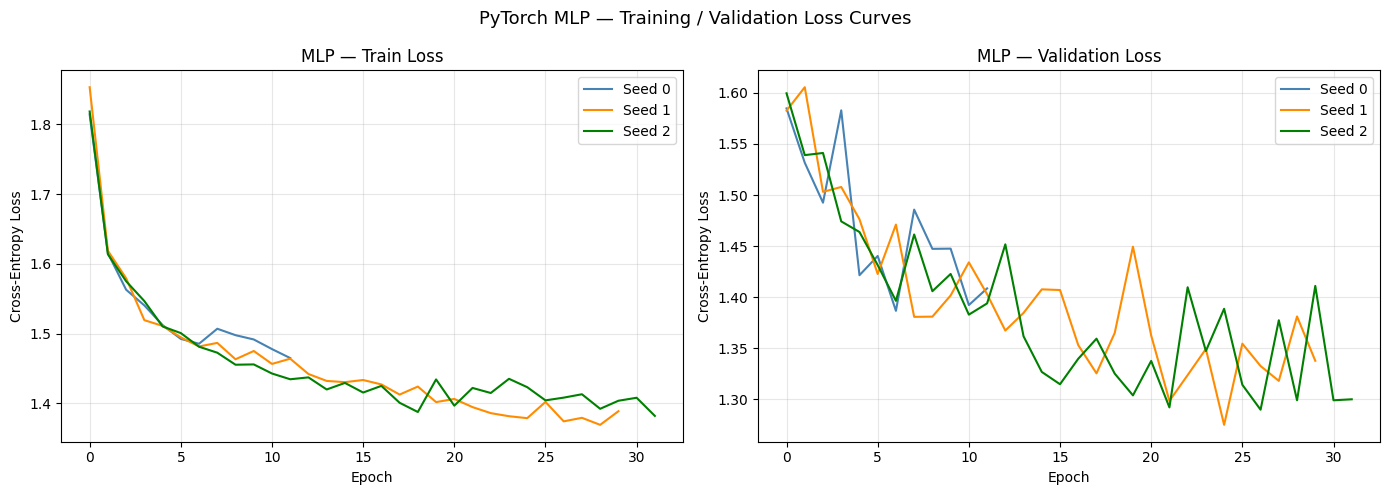

Saved: figures/mlp_loss_curves.png (backed up to Drive)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['steelblue', 'darkorange', 'green']
for s, (tl, vl) in enumerate(zip(train_loss_all, val_loss_all)):
    axes[0].plot(tl, color=colors[s], label=f'Seed {s}')
    axes[1].plot(vl, color=colors[s], label=f'Seed {s}')
for ax, title in zip(axes, ['Train Loss', 'Validation Loss']):
    ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss')
    ax.set_title(f'MLP — {title}'); ax.legend(); ax.grid(True, alpha=0.3)
plt.suptitle('PyTorch MLP — Training / Validation Loss Curves', fontsize=13)
plt.tight_layout()
plt.savefig('figures/mlp_loss_curves.png', dpi=150)
!cp figures/mlp_loss_curves.png /content/drive/MyDrive/ann_cw1/figures/ 2>/dev/null || true
plt.show()
print('Saved: figures/mlp_loss_curves.png (backed up to Drive)')

## Confusion Matrix (best val seed)

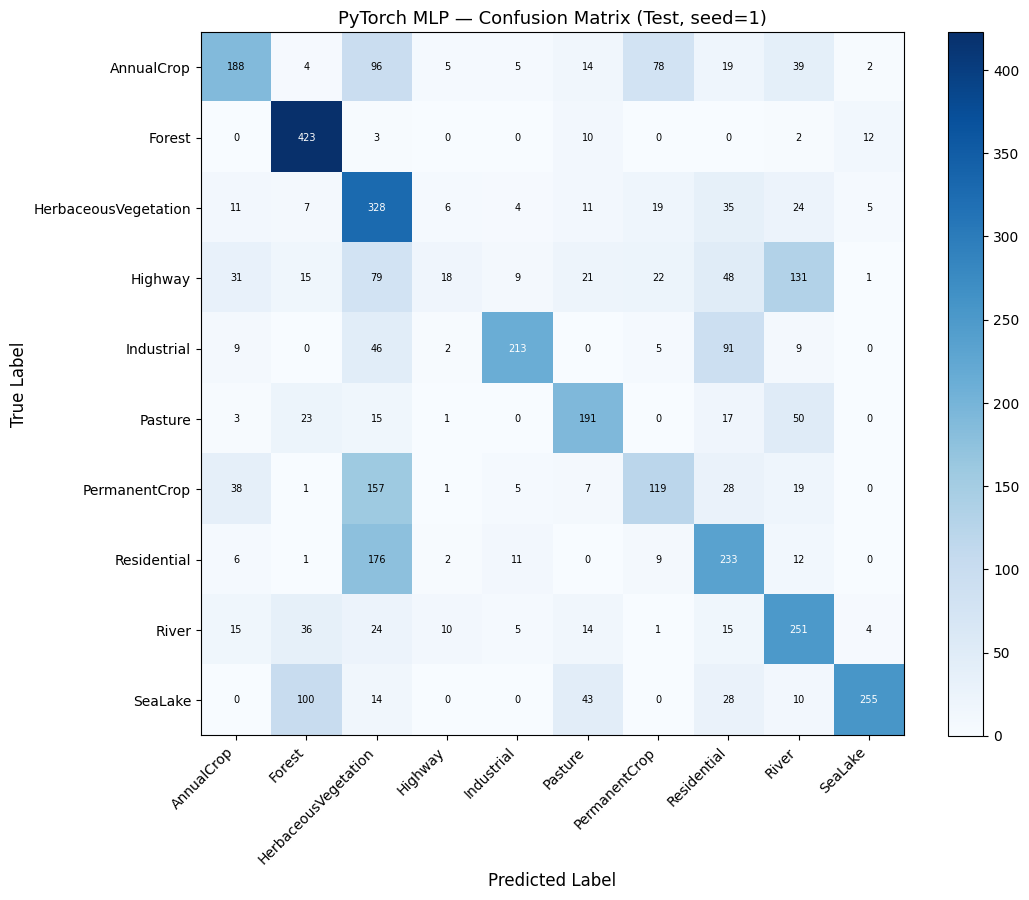

Saved: figures/confusion_mlp_test.png (backed up to Drive)


In [8]:
best_seed = max(mlp_results, key=lambda r: r['val_macro_f1'])['seed']
best_model = make_mlp().to(DEVICE)
best_model.load_state_dict(torch.load(f'checkpoints/mlp_seed{best_seed}.pt'))
y_true, y_pred = evaluate_metrics(best_model, test_loader)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im, ax=ax)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title(f'PyTorch MLP — Confusion Matrix (Test, seed={best_seed})', fontsize=13)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i,j], ha='center', va='center', fontsize=7,
                color='white' if cm[i,j] > cm.max()/2 else 'black')
plt.tight_layout()
plt.savefig('figures/confusion_mlp_test.png', dpi=150)
!cp figures/confusion_mlp_test.png /content/drive/MyDrive/ann_cw1/figures/ 2>/dev/null || true
plt.show()
print('Saved: figures/confusion_mlp_test.png (backed up to Drive)')

---
## ✅ Notebook 05 Complete
**Next:** Run `06_cnn_pytorch.ipynb` for the T3b CNN neural model.